# Tugas - Klasifikasi dengan Decision Tree

| Nama | NRP |
|------|-----|
| Faiz Farrosian Karim | 5054251027 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model Decision Tree Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset yang digunakan adalah **Company Bankruptcy Prediction Dataset**, berisi data rasio-rasio keuangan perusahaan di Taiwan beserta label apakah perusahaan tersebut bangkrut atau tidak.

Tujuan utama dari tugas ini adalah memahami cara kerja Decision Tree secara praktik, khususnya:
1. Perbedaan hasil antara kriteria split Gini Impurity dan Entropy
2. Pengaruh regularisasi (max_depth) terhadap gejala overfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model.
3. Eksperimen Model
   - Bangun model Decision Tree dengan kriteria Gini dan Entropy.
   - Lakukan eksperimen regularisasi dengan variasi nilai max_depth.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

sns.set_style('whitegrid')
%matplotlib inline

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv('bankruptcy.csv')
df.columns = df.columns.str.strip()  # ada spasi ekstra di beberapa nama kolom, jadi dirapikan dulu

print('Jumlah baris dan kolom:', df.shape)
df.info()

Jumlah baris dan kolom: (6819, 96)
<class 'pandas.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 96 columns):
 #   Column                                                   Non-Null Count  Dtype  
---  ------                                                   --------------  -----  
 0   Bankrupt?                                                6819 non-null   int64  
 1   ROA(C) before interest and depreciation before interest  6819 non-null   float64
 2   ROA(A) before interest and % after tax                   6819 non-null   float64
 3   ROA(B) before interest and depreciation after tax        6819 non-null   float64
 4   Operating Gross Margin                                   6819 non-null   float64
 5   Realized Sales Gross Margin                              6819 non-null   float64
 6   Operating Profit Rate                                    6819 non-null   float64
 7   Pre-tax net Interest Rate                                6819 non-null   float64
 8   Afte

In [3]:
# Statistik deskriptif
df.describe()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
count,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,...,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.0,6819.000000
mean,0.032263,0.505180,0.558625,0.553589,0.607948,0.607929,0.998755,0.797190,0.809084,0.303623,...,0.807760,1.862942e+07,0.623915,0.607946,0.840402,0.280365,0.027541,0.565358,1.0,0.047578
std,0.176710,0.060686,0.065620,0.061595,0.016934,0.016916,0.013010,0.012869,0.013601,0.011163,...,0.040332,3.764501e+08,0.012290,0.016934,0.014523,0.014463,0.015668,0.013214,0.0,0.050014
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.000000
25%,0.000000,0.476527,0.535543,0.527277,0.600445,0.600434,0.998969,0.797386,0.809312,0.303466,...,0.796750,9.036205e-04,0.623636,0.600443,0.840115,0.276944,0.026791,0.565158,1.0,0.024477
50%,0.000000,0.502706,0.559802,0.552278,0.605997,0.605976,0.999022,0.797464,0.809375,0.303525,...,0.810619,2.085213e-03,0.623879,0.605998,0.841179,0.278778,0.026808,0.565252,1.0,0.033798
75%,0.000000,0.535563,0.589157,0.584105,0.613914,0.613842,0.999095,0.797579,0.809469,0.303585,...,0.826455,5.269777e-03,0.624168,0.613913,0.842357,0.281449,0.026913,0.565725,1.0,0.052838
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,9.820000e+09,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.000000


In [4]:
# Jumlah missing value tiap kolom
missing = df.isnull().sum()
print('Total missing value di seluruh dataset:', missing.sum())
missing[missing > 0]

Total missing value di seluruh dataset: 0


Series([], dtype: int64)

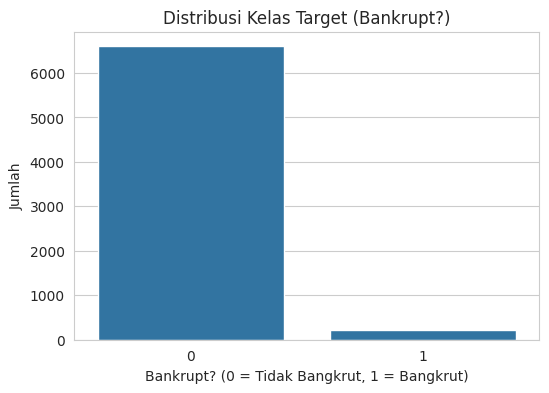

Bankrupt?
0    6599
1     220
Name: count, dtype: int64

Persentase tiap kelas:
Bankrupt?
0    96.77372
1     3.22628
Name: proportion, dtype: float64


In [5]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
plt.figure(figsize=(6,4))
sns.countplot(x='Bankrupt?', data=df)
plt.title('Distribusi Kelas Target (Bankrupt?)')
plt.xlabel('Bankrupt? (0 = Tidak Bangkrut, 1 = Bangkrut)')
plt.ylabel('Jumlah')
plt.show()

print(df['Bankrupt?'].value_counts())
print()
print('Persentase tiap kelas:')
print(df['Bankrupt?'].value_counts(normalize=True) * 100)

5 fitur dengan korelasi tertinggi terhadap target:
['Net Income to Total Assets', 'ROA(A) before interest and % after tax', 'ROA(B) before interest and depreciation after tax', 'ROA(C) before interest and depreciation before interest', 'Net worth/Assets']


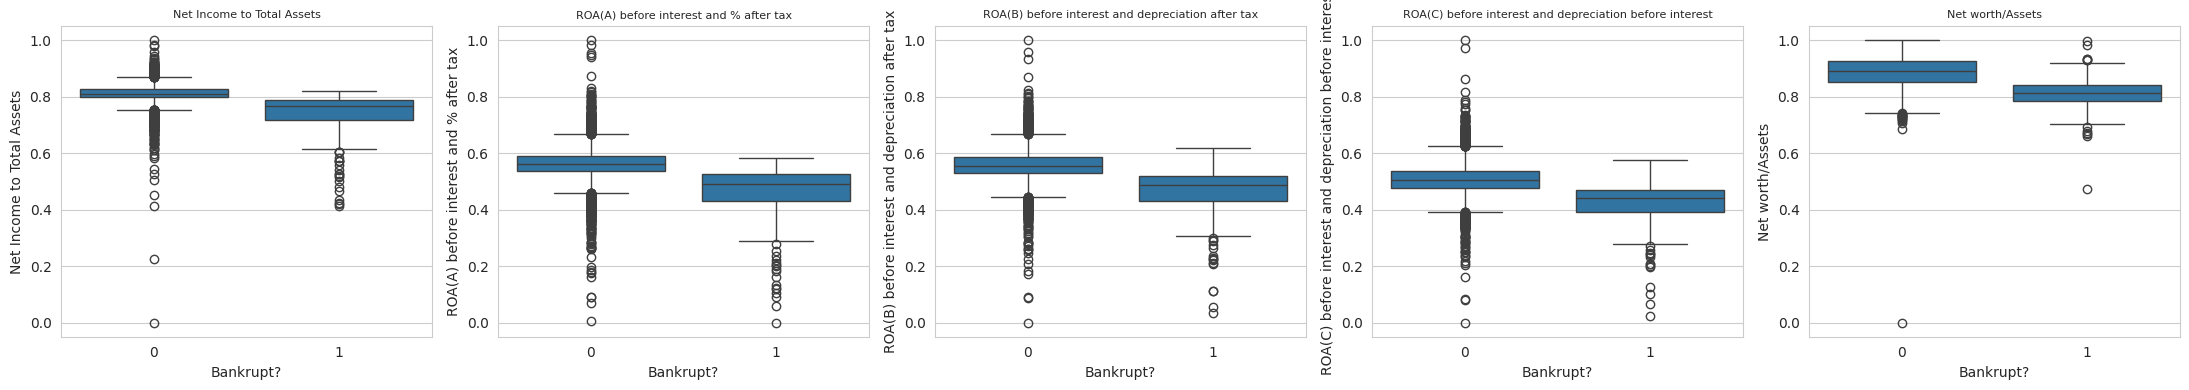

In [6]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau pairplot), dibedakan berdasarkan kelas target.
# Ini membantu melihat apakah ada fitur yang punya batas pemisah yang jelas antar kelas.
# Karena jumlah fitur sangat banyak (95 fitur), untuk melihat hubungan fitur dengan target
# saya ambil 5 fitur yang korelasinya paling tinggi (secara absolut) dengan kolom target.
corr_target = df.corr(numeric_only=True)['Bankrupt?'].drop('Bankrupt?').abs().sort_values(ascending=False)
top_features = corr_target.head(5).index
print('5 fitur dengan korelasi tertinggi terhadap target:')
print(top_features.tolist())

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for i, col in enumerate(top_features):
    sns.boxplot(x='Bankrupt?', y=col, data=df, ax=axes[i])
    axes[i].set_title(col, fontsize=8)
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

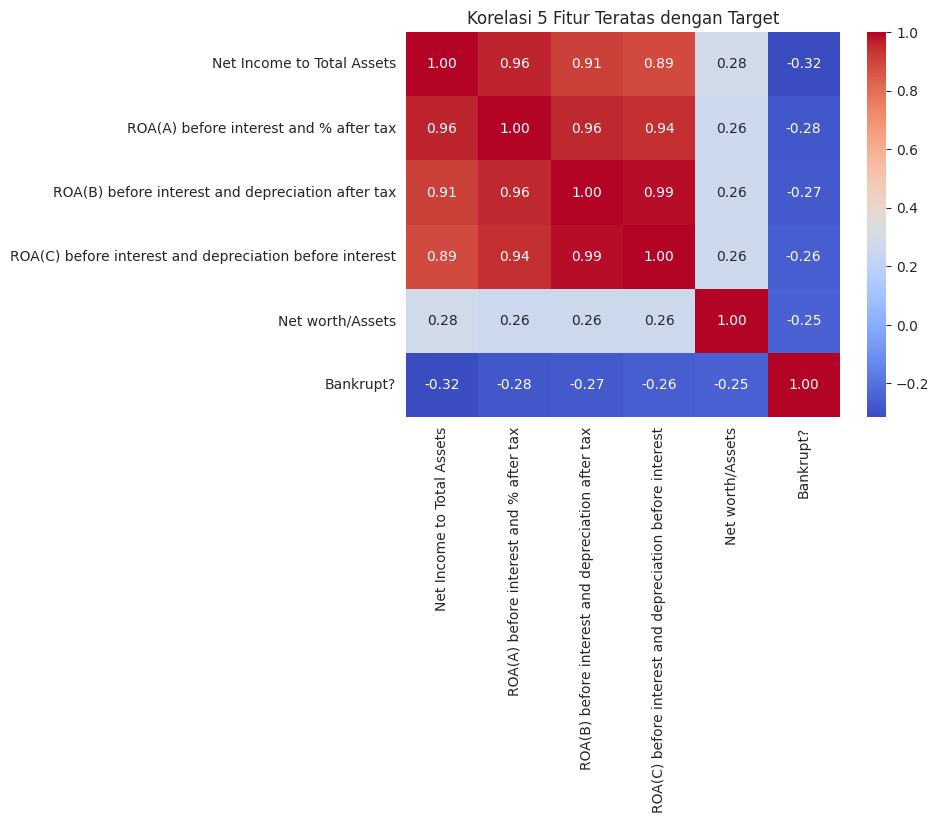

In [7]:
# EDA tambahan: heatmap korelasi antar fitur teratas dan target
fitur_heatmap = top_features.tolist() + ['Bankrupt?']
plt.figure(figsize=(7, 5))
sns.heatmap(df[fitur_heatmap].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi 5 Fitur Teratas dengan Target')
plt.show()

# 2. Preprocessing

In [8]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.
# Dari pengecekan sebelumnya, dataset ini tidak memiliki missing value sama sekali,
# jadi tidak diperlukan strategi imputasi apapun di tahap ini.
print('Total missing value:', df.isnull().sum().sum())

Total missing value: 0


In [9]:
# Jika terdapat fitur kategorikal, lakukan encoding yang sesuai (misalnya One-Hot Encoding atau Ordinal Encoding).
# Catatan: Decision Tree secara konsep bisa menangani fitur kategorikal secara langsung tanpa One-Hot Encoding,
# tetapi implementasi DecisionTreeClassifier pada scikit-learn tetap mengharuskan input berupa angka.
print(df.dtypes.value_counts())
# Semua kolom sudah berupa numerik (int64/float64), sehingga tidak diperlukan
# One-Hot Encoding maupun Ordinal Encoding.

float64    93
int64       3
Name: count, dtype: int64


In [10]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.
X = df.drop(columns=['Bankrupt?'])
y = df['Bankrupt?']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Ukuran X_train:', X_train.shape)
print('Ukuran X_test :', X_test.shape)
print()
print('Distribusi y_train (%):')
print(y_train.value_counts(normalize=True) * 100)
print()
print('Distribusi y_test (%):')
print(y_test.value_counts(normalize=True) * 100)

Ukuran X_train: (5455, 95)
Ukuran X_test : (1364, 95)

Distribusi y_train (%):
Bankrupt?
0    96.773602
1     3.226398
Name: proportion, dtype: float64

Distribusi y_test (%):
Bankrupt?
0    96.774194
1     3.225806
Name: proportion, dtype: float64


**Catatan penting:** Decision Tree tidak memerlukan feature scaling (StandardScaler/MinMaxScaler). Split pada Decision Tree dilakukan berdasarkan threshold per fitur satu per satu, bukan berdasarkan jarak antar titik seperti pada KNN atau SVM. Jadi kalian tidak perlu melakukan scaling pada tahap ini.

# 3. Eksperimen Model

## 3.1 Decision Tree dengan Kriteria Gini

Gini Impurity adalah kriteria default pada DecisionTreeClassifier di scikit-learn. Kriteria ini mengukur peluang kesalahan klasifikasi jika sebuah sampel dipilih secara acak dari suatu node.

In [11]:
# Inisialisasi dan latih model DecisionTreeClassifier dengan criterion='gini' menggunakan train set.
dt_gini = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42)
dt_gini.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no

In [12]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
y_pred_gini = dt_gini.predict(X_test)

## 3.2 Decision Tree dengan Kriteria Entropy

Entropy (Information Gain) adalah kriteria alternatif yang mengukur tingkat ketidakpastian distribusi kelas pada suatu node.

In [13]:
# Inisialisasi dan latih model DecisionTreeClassifier dengan criterion='entropy' menggunakan train set.
# Gunakan nilai hyperparameter lain yang sama seperti model Gini di atas, agar perbandingan adil.
dt_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=42)
dt_entropy.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

In [14]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
y_pred_entropy = dt_entropy.predict(X_test)

## 3.3 Eksperimen Regularisasi: Pengaruh max_depth terhadap Overfitting

Decision Tree yang dibiarkan tumbuh tanpa batas cenderung overfitting terhadap data training. Pada bagian ini kalian akan mengamati bagaimana perubahan nilai max_depth memengaruhi akurasi training dan testing.

In [15]:
# Latih beberapa model DecisionTreeClassifier dengan variasi nilai max_depth,
# misalnya 1, 2, 3, 5, 10, dan None (tanpa batas kedalaman).
# Gunakan kriteria split terbaik dari salah satu percobaan sebelumnya (Gini atau Entropy).
depth_list = [1, 2, 3, 5, 10, None]
train_acc_list = []
test_acc_list = []

# Hitung akurasi pada train set dan test set untuk setiap nilai max_depth yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
for depth in depth_list:
    model = DecisionTreeClassifier(criterion='gini', max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    train_acc_list.append(accuracy_score(y_train, model.predict(X_train)))
    test_acc_list.append(accuracy_score(y_test, model.predict(X_test)))

hasil_depth = pd.DataFrame({
    'max_depth': [str(d) for d in depth_list],
    'train_accuracy': train_acc_list,
    'test_accuracy': test_acc_list
})
hasil_depth

,max_depth,train_accuracy,test_accuracy
0,1,0.967736,0.967742
1,2,0.969936,0.969941
2,3,0.972319,0.969941
3,5,0.977452,0.968475
4,10,0.994684,0.960411
5,None,1.000000,0.961144


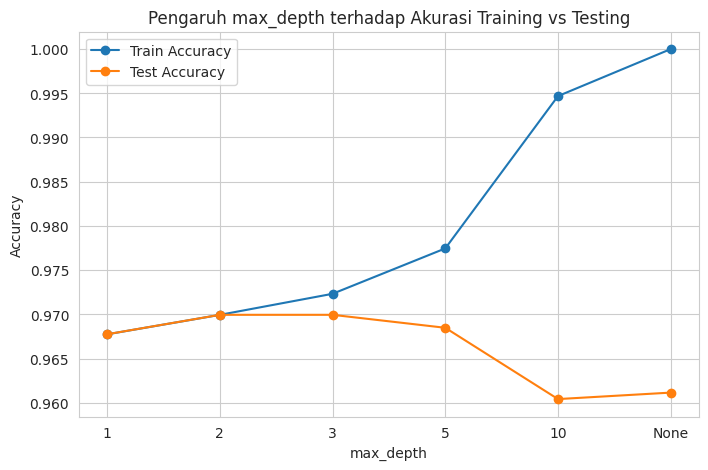

In [16]:
# Plot grafik akurasi training vs testing terhadap max_depth dalam satu chart.
# Amati pada titik berapa model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).
plt.figure(figsize=(8, 5))
plt.plot(hasil_depth['max_depth'], hasil_depth['train_accuracy'], marker='o', label='Train Accuracy')
plt.plot(hasil_depth['max_depth'], hasil_depth['test_accuracy'], marker='o', label='Test Accuracy')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Pengaruh max_depth terhadap Akurasi Training vs Testing')
plt.legend()
plt.show()

# 4. Evaluasi Model

In [17]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model Gini dan Entropy.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
def get_metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred)
    }

metrics_gini = get_metrics(y_test, y_pred_gini)
metrics_entropy = get_metrics(y_test, y_pred_entropy)

df_metrics = pd.DataFrame([metrics_gini, metrics_entropy], index=['Gini', 'Entropy'])
df_metrics

,Accuracy,Precision,Recall,F1-Score
Gini,0.968475,0.514286,0.409091,0.455696
Entropy,0.966276,0.473684,0.409091,0.439024


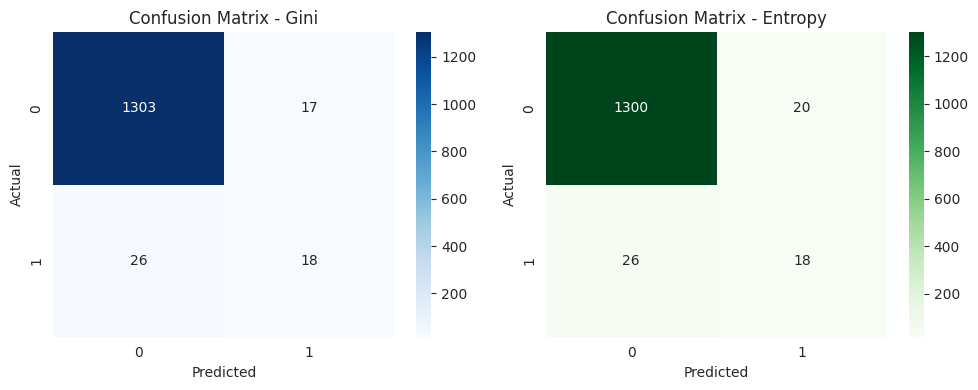

In [18]:
# Tampilkan Confusion Matrix untuk model Gini dan Entropy dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
cm_gini = confusion_matrix(y_test, y_pred_gini)
cm_entropy = confusion_matrix(y_test, y_pred_entropy)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(cm_gini, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix - Gini')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(cm_entropy, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Confusion Matrix - Entropy')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

Model dengan performa terbaik: Gini


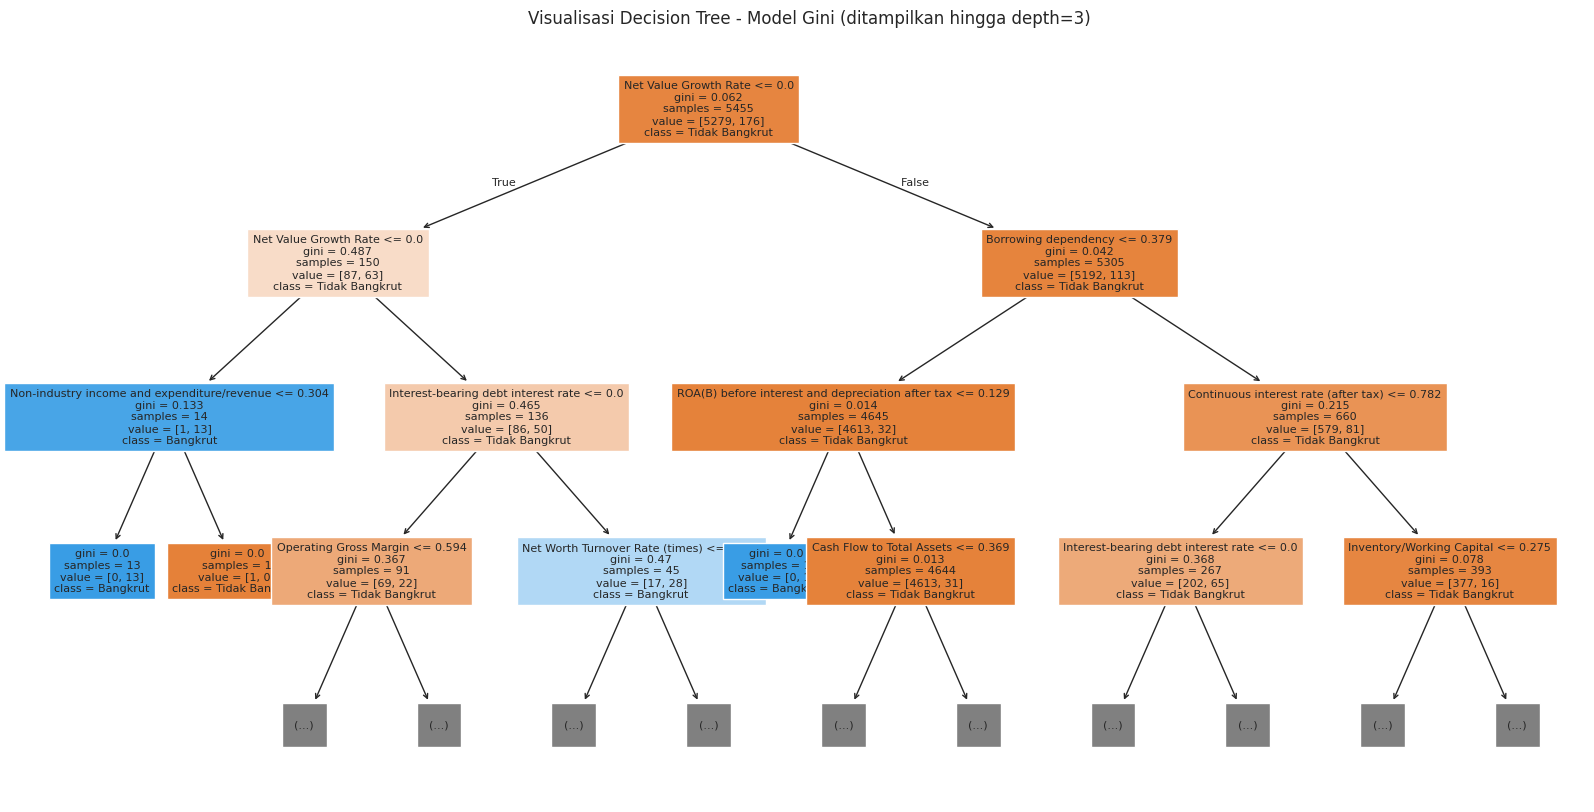

In [19]:
# Visualisasikan struktur Decision Tree (gunakan plot_tree) untuk model dengan performa terbaik.
# Batasi kedalaman visualisasi (misalnya max_depth=2 atau 3 pada parameter plot_tree) agar tetap mudah dibaca.
# Pilih model dengan performa terbaik (berdasarkan F1-Score, karena data imbalanced)
if metrics_gini['F1-Score'] >= metrics_entropy['F1-Score']:
    best_model, best_name = dt_gini, 'Gini'
else:
    best_model, best_name = dt_entropy, 'Entropy'
print('Model dengan performa terbaik:', best_name)

# Visualisasikan struktur Decision Tree, dibatasi hingga depth=3 agar tetap mudah dibaca
plt.figure(figsize=(20, 10))
plot_tree(best_model, max_depth=3, feature_names=X.columns, class_names=['Tidak Bangkrut', 'Bangkrut'],
          filled=True, fontsize=8)
plt.title(f'Visualisasi Decision Tree - Model {best_name} (ditampilkan hingga depth=3)')
plt.show()

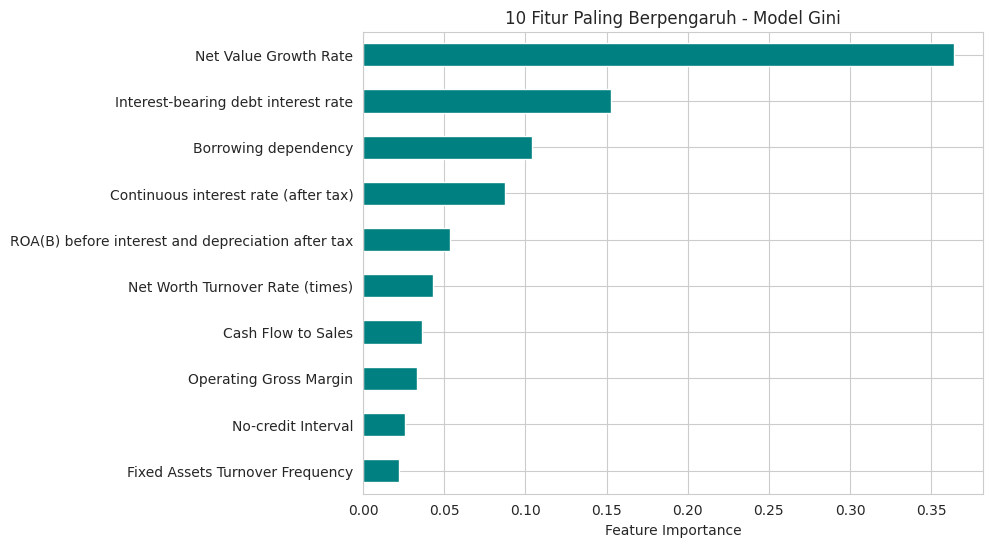

Net Value Growth Rate                                0.363853
Interest-bearing debt interest rate                  0.153040
Borrowing dependency                                 0.103798
Continuous interest rate (after tax)                 0.087468
ROA(B) before interest and depreciation after tax    0.053356
Net Worth Turnover Rate (times)                      0.042959
Cash Flow to Sales                                   0.036425
Operating Gross Margin                               0.033092
No-credit Interval                                   0.025702
Fixed Assets Turnover Frequency                      0.022097
dtype: float64

In [20]:
# Tampilkan feature importance dari model terbaik dalam bentuk bar chart horizontal.
# Urutkan dari fitur yang paling berpengaruh.
importances = pd.Series(best_model.feature_importances_, index=X.columns)
top10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 6))
top10.sort_values().plot(kind='barh', color='teal')
plt.title(f'10 Fitur Paling Berpengaruh - Model {best_name}')
plt.xlabel('Feature Importance')
plt.show()

top10

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa Decision Tree dengan kriteria Gini vs Entropy. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Jelaskan temuan dari eksperimen regularisasi (max_depth). Pada nilai berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Fitur apa yang paling berpengaruh terhadap prediksi model, berdasarkan feature importance?

**JAWABAN:**

**Gini vs Entropy.** Berdasarkan tabel metrik pada bagian 4, model Gini menghasilkan Accuracy 0.968 dan F1-Score 0.456, sedangkan model Entropy menghasilkan Accuracy 0.966 dan F1-Score 0.439. Selisihnya kecil, jadi bisa dibilang performa keduanya tidak berbeda signifikan. Hal ini wajar karena secara matematis, Gini Impurity dan Entropy sama-sama mengukur "ketidakmurnian" suatu node, hanya rumus perhitungannya yang berbeda, sehingga pada sebagian besar kasus kedua kriteria ini cenderung memilih split fitur yang mirip. Entropy sedikit lebih "mahal" secara komputasi karena menggunakan fungsi logaritma, sedangkan Gini lebih cepat dihitung — ini salah satu alasan Gini dijadikan default di scikit-learn.

**Pengaruh max_depth (overfitting).** Dari tabel dan grafik akurasi training vs testing terlihat pola berikut: pada max_depth kecil (1-3), akurasi training dan testing naik bersama-sama (dari sekitar 0.968 ke 0.970), dan keduanya masih berdekatan. Titik terbaik pada testing tercapai di sekitar max_depth=2-3 (akurasi test ≈ 0.970). Setelah itu, begitu max_depth diperbesar ke 10 atau None (tanpa batas), akurasi training terus naik hingga mendekati bahkan mencapai 1.0 (menghafal seluruh data training), sedangkan akurasi testing justru sedikit menurun ke sekitar 0.960-0.961. Melebarnya celah (gap) antara garis train dan test inilah ciri khas overfitting: model menjadi terlalu kompleks dan "menghafal" data training beserta noise-nya, sehingga kurang general terhadap data baru.

**Feature importance.** Berdasarkan bar chart feature importance dari model terbaik (Gini), fitur yang paling berpengaruh adalah Net Value Growth Rate, disusul Interest-bearing debt interest rate, Borrowing dependency, Continuous interest rate (after tax), dan ROA(B) before interest and depreciation after tax. Mayoritas fitur teratas ini berkaitan dengan pertumbuhan nilai perusahaan, beban bunga utang, dan profitabilitas — sesuai dugaan awal, karena secara bisnis perusahaan yang mendekati bangkrut umumnya ditandai dengan pertumbuhan yang melambat/negatif, ketergantungan pinjaman yang tinggi, dan profitabilitas yang menurun.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba pruning dengan ccp_alpha, membandingkan dengan model lain, atau mencoba variasi hyperparameter lain seperti min_samples_leaf), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

**KESIMPULAN:**

Model Decision Tree berhasil dilatih untuk memprediksi status kebangkrutan perusahaan berdasarkan rasio-rasio keuangannya. Kriteria split Gini dan Entropy memberikan hasil yang hampir sama, sehingga pemilihan salah satu dari keduanya tidak terlalu berdampak besar pada kasus ini. Yang lebih berpengaruh justru pengaturan max_depth: pohon yang terlalu dangkal membuat model underfitting, sedangkan pohon yang dibiarkan tumbuh tanpa batas membuat model overfitting terhadap data training.

Perlu dicatat juga bahwa dataset ini sangat imbalanced (jumlah perusahaan yang bangkrut jauh lebih sedikit dibanding yang tidak bangkrut), sehingga metrik Accuracy saja bisa menyesatkan — Precision, Recall, dan F1-Score pada kelas minoritas (bangkrut) lebih penting untuk diperhatikan.

**SARAN untuk eksperimen selanjutnya:**
- Mencoba pruning dengan parameter `ccp_alpha` agar pohon lebih sederhana tanpa harus menebak max_depth secara manual.
- Menangani ketidakseimbangan kelas, misalnya dengan `class_weight='balanced'`, oversampling (SMOTE), atau undersampling.
- Membandingkan performa Decision Tree dengan model lain seperti Random Forest atau Logistic Regression sebagai pembanding.
- Melakukan hyperparameter tuning tambahan (misalnya `min_samples_leaf`, `min_samples_split`) menggunakan GridSearchCV.